# Fitting a seasonal cycle

Fit the seasonal cycle and linear trend of sea surface temperature, remove them, and map
the amplitude, phase, and trend.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import xclimatology  # noqa: F401 (registers the .climatology accessor)

## Load the data

We use monthly ERSST v5 sea surface temperature for 1970–2021 on a 2° grid, from the
xarray tutorial datasets. Each monthly mean is stamped on the first day of its month.
Moving it to mid-month, the time it represents, keeps the fitted phases from shifting
by half a month.

In [2]:
sst = xr.tutorial.load_dataset("ersstv5")["sst"]
sst["time"] = sst["time"] + pd.Timedelta(days=14)
sst

<xarray.DataArray 'sst' (time: 624, lat: 89, lon: 180)> Size: 40MB
array([[[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
...
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        [-1.8, -1.8, -1.8, ..., -1.8, -1.8, -1.8],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]]],
      shape=(624, 89, 180), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1970-01-15 1970-02-15 ... 2021-12-15
  * lat      (lat) float32 356B 88.0 86.0 84.0 82.0 ... -82.0 -84.0 -86.0 -88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Attributes:
    long_name:     Monthly Means of Sea Surface Temperature
    units:         degC
    var_desc:      Sea Surface Temperature
    level_desc:    Surface
    statistic:     Mean
    dataset:       NOAA Extended Reconstructed SST V5
    parent_stat:   Individual Values
    actual_range:  [-1.8     42.32636]
    valid_range:   [-1.8 45. ]

Monthly data stored as "months since" cannot be decoded by `xr.decode_cf` outside the
`360_day` calendar. Build the time coordinate with
`xr.date_range(start, periods=n, freq="MS")` and shift it the same way.

## Fit the climatology

`sst.climatology(**model)` fits, at each grid point, the climatology

\begin{align*}
\bar{y}(t) &= c_0 + c_1 (t - t_{\mathrm{mid}})
+ \sum_{k=1}^{K}\left[a_k \cos(k\omega t) + b_k \sin(k\omega t)\right], \\
\omega &= \frac{2\pi}{T},
\end{align*}

with $t$ in years, $t_{\mathrm{mid}}$ the middle of the record, period $T = 1$ year, and
$K = 2$ harmonics (annual and semiannual). $c_0$ is the intercept at $t_{\mathrm{mid}}$ and
$c_1$ the linear trend. `n_harmonics` sets $K$, `period` and `period_units` set $T$, and
`detrend_degree` sets the degree of the polynomial.
`sst - clim` is the anomaly $y' = y - \bar{y}$.

In [3]:
model = dict(n_harmonics=2, period=1, period_units="year", detrend_degree=1)

clim = sst.climatology(**model)
anomaly = sst - clim
clim

<xarray.DataArray 'sst' (time: 624, lat: 89, lon: 180)> Size: 80MB
array([[[-1.80078151, -1.80069221, -1.8007046 , ..., -1.80079727,
         -1.80086392, -1.80088763],
        [-1.80065193, -1.80077033, -1.80086912, ..., -1.80021783,
         -1.80048288, -1.80054795],
        [-1.80005739, -1.80026866, -1.80043063, ..., -1.80047987,
         -1.80030421, -1.80013502],
        ...,
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]],

       [[-1.80189185, -1.80180401, -1.80176802, ..., -1.80157832,
         -1.80180814, -1.80196494],
        [-1.80180684, -1.80202041, -1.80216658, ..., -1.80054307,
         -1.8012842 , -1.80153652],
        [-1.80005567, -1.80066977, -1.80107353, ..., -1.8004645 ,
         -1.8002951 , -1.80013097],
...
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]],

       [[-1.79642549, -1.79653562, -1.79668525, ..., -1.7972481 ,
         -1.79676194, -1.79639152],
        [-1.79646775, -1.79615311, -1.79598196, ..., -1.79899275,
         -1.79753805, -1.79698014],
        [-1.79994345, -1.79875778, -1.79800902, ..., -1.79952884,
         -1.79970064, -1.79986708],
        ...,
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]]], shape=(624, 89, 180))
Coordinates:
  * time     (time) datetime64[ns] 5kB 1970-01-15 1970-02-15 ... 2021-12-15
  * lat      (lat) float32 356B 88.0 86.0 84.0 82.0 ... -82.0 -84.0 -86.0 -88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Attributes:
    long_name:     Monthly Means of Sea Surface Temperature
    units:         degC
    var_desc:      Sea Surface Temperature
    level_desc:    Surface
    statistic:     Mean
    dataset:       NOAA Extended Reconstructed SST V5
    parent_stat:   Individual Values
    actual_range:  [-1.8     42.32636]
    valid_range:   [-1.8 45. ]

At a single grid point:

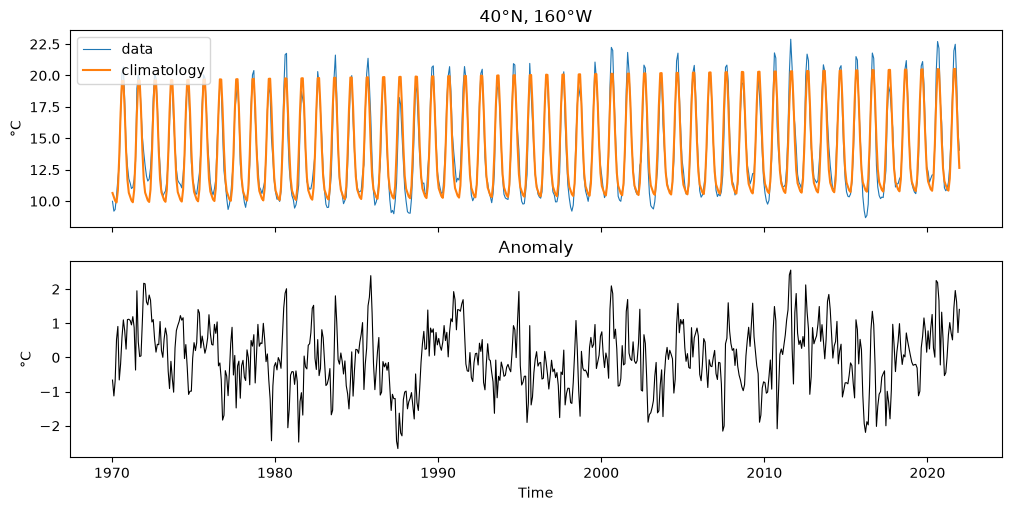

In [4]:
point = dict(lat=40, lon=200)

fig, axes = plt.subplots(nrows=2, figsize=(10, 5), sharex=True, constrained_layout=True)
sst.sel(**point).plot(ax=axes[0], lw=0.8, label="data")
clim.sel(**point).plot(ax=axes[0], lw=1.5, label="climatology")
axes[0].set(title="40°N, 160°W", xlabel="", ylabel="°C")
axes[0].legend(loc="upper left")
anomaly.sel(**point).plot(ax=axes[1], lw=0.8, color="k")
axes[1].set(title="Anomaly", ylabel="°C");

## Compare with calendar-month means

A common alternative is the mean of each calendar month,
`sst.groupby("time.month").mean()`. It repeats the same 12 values every year, while
`climatology()` also includes the trend. At the start and end of the record:

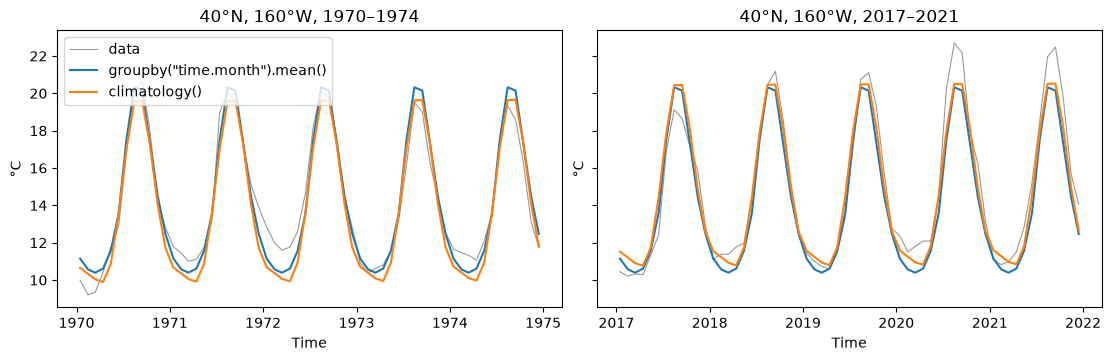

In [5]:
by_month = sst.groupby("time.month").mean()
by_month = by_month.sel(month=sst["time"].dt.month)  # repeat on the original time axis

fig, axes = plt.subplots(ncols=2, figsize=(11, 3.5), sharey=True, constrained_layout=True)
for ax, years in zip(axes, (slice("1970", "1974"), slice("2017", "2021"))):
    sst.sel(**point).sel(time=years).plot(ax=ax, color="0.6", lw=0.8, label="data")
    by_month.sel(**point).sel(time=years).plot(ax=ax, lw=1.5, label='groupby("time.month").mean()')
    clim.sel(**point).sel(time=years).plot(ax=ax, lw=1.5, label="climatology()")
    ax.set(title=f"40°N, 160°W, {years.start}–{years.stop}", ylabel="°C")
axes[0].legend(loc="upper left");

## Amplitude and phase

`sst.climatology.coefficients(**model)` returns the fitted coefficients with the
amplitude $A_k$ and phase $\phi_k$ of each harmonic,

\begin{align*}
a_k \cos(k\omega t) + b_k \sin(k\omega t) &= A_k \cos(k\omega t - \phi_k), \\
A_k &= \sqrt{a_k^2 + b_k^2}, \\
\phi_k &= \mathrm{atan2}(b_k, a_k).
\end{align*}

Harmonic $k$ peaks where $k\omega t - \phi_k = 2\pi n$. `atan2` returns $\phi_k$ in
$[-\pi, \pi]$, so the first peak after January 1 is at

$$
t_{\mathrm{peak},k} = \frac{\phi_k \bmod 2\pi}{k\omega}
$$

years. $t_{\mathrm{peak},k}$ is the peak of the fitted sinusoid, which repeats every $T/k$, and can
differ from the time of the largest observed value.

In [6]:
coefs = sst.climatology.coefficients(**model)
coefs

<xarray.Dataset> Size: 1MB
Dimensions:    (lat: 89, lon: 180, harmonic: 2, degree: 1)
Coordinates:
  * lat        (lat) float32 356B 88.0 86.0 84.0 82.0 ... -84.0 -86.0 -88.0
  * lon        (lon) float32 720B 0.0 2.0 4.0 6.0 ... 352.0 354.0 356.0 358.0
  * harmonic   (harmonic) int64 16B 1 2
  * degree     (degree) int64 8B 1
Data variables:
    mean       (lat, lon) float64 128kB -1.799 -1.799 -1.799 ... nan nan nan
    cos        (lat, lon, harmonic) float64 256kB 0.0008098 -6.221e-05 ... nan
    sin        (lat, lon, harmonic) float64 256kB -0.000824 -0.001084 ... nan
    amplitude  (lat, lon, harmonic) float64 256kB 0.001155 0.001086 ... nan nan
    phase      (lat, lon, harmonic) float64 256kB -0.7941 -1.628 ... nan nan
    trend      (lat, lon, degree) float64 128kB 5.447e-05 5.152e-05 ... nan nan
Attributes:
    period:          1
    period_units:    year
    n_harmonics:     2
    detrend_degree:  1
    t0:              1995.995890410959

Map the annual amplitude $A_1$ and the day of year of the annual peak, approximately $365.25\,t_{\mathrm{peak},1}$:

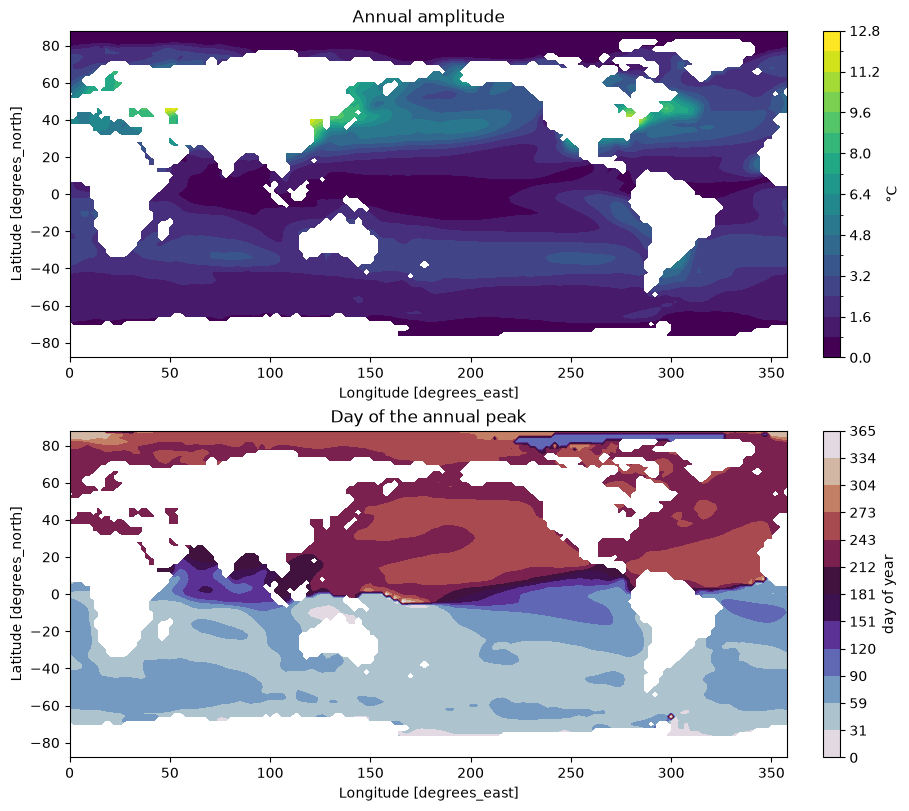

In [7]:
annual = coefs.sel(harmonic=1)
peak_day = (annual["phase"] % (2 * np.pi)) / (2 * np.pi) * 365.25

fig, axes = plt.subplots(nrows=2, figsize=(9, 8), constrained_layout=True)
annual["amplitude"].plot.contourf(ax=axes[0], levels=21, cbar_kwargs={"label": "°C"})
axes[0].set_title("Annual amplitude")
month_starts = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334, 365]  # day of year of each month start
peak_day.plot.contourf(
    ax=axes[1], cmap="twilight", levels=month_starts, cbar_kwargs={"label": "day of year", "ticks": month_starts}
)
axes[1].set_title("Day of the annual peak");

The annual harmonic peaks near the end of August in the Northern Hemisphere and near the
end of February in the Southern Hemisphere.

## Trend

`polynomial` holds the coefficient $c_p$ of $(t - t_{\mathrm{mid}})^p$ for each degree $p$,
with $t$ in `period_units`. Degree 1 is the trend $c_1$ per year, so multiplying by 10
gives the trend per decade.

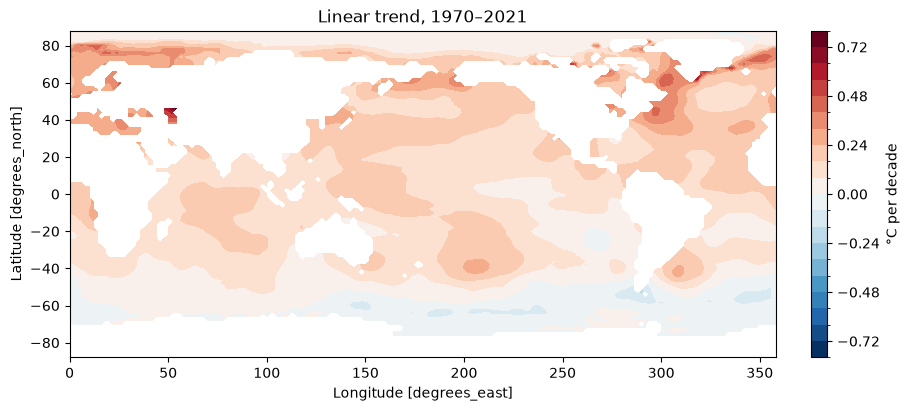

In [8]:
trend = coefs["polynomial"].sel(degree=1) * 10

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
trend.plot.contourf(ax=ax, levels=21, cbar_kwargs={"label": "°C per decade"})
ax.set_title("Linear trend, 1970–2021");